In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("D:/DATA/aitpune/college study thingy/ml/dataset/emails.csv")
print(df.shape)
df.head()

(5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), str(1)
memory usage: 118.5 MB


In [4]:
df.describe()

,the,to,ect,and,for,of,a,you,hou,in,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
count,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,...,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000
mean,6.640565,6.188128,5.143852,3.075599,3.124710,2.627030,55.517401,2.466551,2.024362,10.600155,...,0.005027,0.012568,0.010634,0.098028,0.004254,0.006574,0.004060,0.914733,0.006961,0.290023
std,11.745009,9.534576,14.101142,6.045970,4.680522,6.229845,87.574172,4.314444,6.967878,19.281892,...,0.105788,0.199682,0.116693,0.569532,0.096252,0.138908,0.072145,2.780203,0.098086,0.453817
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,12.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,3.000000,1.000000,1.000000,2.000000,1.000000,28.000000,1.000000,0.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8.000000,7.000000,4.000000,3.000000,4.000000,2.000000,62.250000,3.000000,1.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,210.000000,132.000000,344.000000,89.000000,47.000000,77.000000,1898.000000,70.000000,167.000000,223.000000,...,4.000000,7.000000,2.000000,12.000000,3.000000,4.000000,3.000000,114.000000,4.000000,1.000000


In [5]:
print("missing values: ")
df.isnull().sum()

missing values: 


Email No.     0
the           0
to            0
ect           0
and           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3002, dtype: int64

In [6]:
print("duplicate rows", df.duplicated().sum())

duplicate rows 0


In [7]:
df = df.drop_duplicates()
print("dataset shape after removing duplicates:", df.shape)

df = df.dropna()
print("datset shape after moving missing values:", df.shape)

dataset shape after removing duplicates: (5172, 3002)
datset shape after moving missing values: (5172, 3002)


In [8]:
print(df['Prediction'].value_counts())

Prediction
0    3672
1    1500
Name: count, dtype: int64


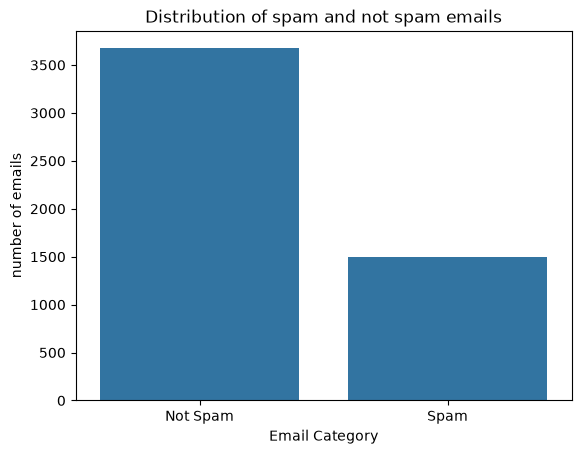

In [9]:
sns.countplot(x='Prediction', data=df)

plt.title('Distribution of spam and not spam emails')
plt.xlabel('Email Category')
plt.ylabel('number of emails')
plt.xticks([0,1], ['Not Spam', 'Spam'])
plt.show()

In [10]:
X = df.drop(['Email No.', 'Prediction'], axis=1)
y = df['Prediction']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5172, 3000)
Target Shape: (5172,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (4137, 3000)
Testing Features: (1035, 3000)
Training Target: (4137,)
Testing Target: (1035,)


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN Model training Completed")

KNN Model training Completed


KNN confusion Matrix
[[576 159]
 [ 13 287]]


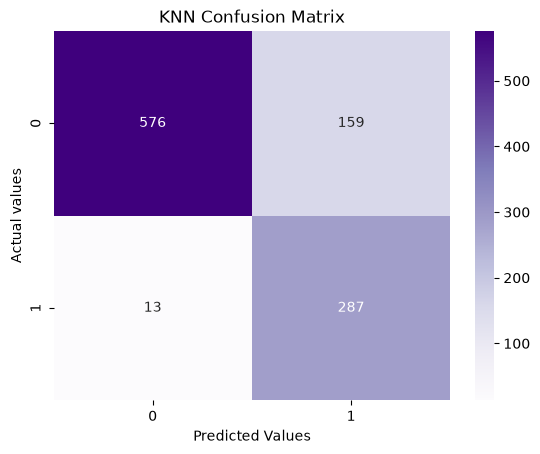

In [14]:
knn_cm = confusion_matrix(y_test, y_pred_knn)
print("KNN confusion Matrix")
print(knn_cm)

sns.heatmap(knn_cm, annot = True, fmt="d", cmap="Purples")
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual values")
plt.show()

In [15]:
svm_model = LinearSVC(
    random_state=42,
    max_iter=5000
)

svm_model.fit(X_train_scaled, y_train)
svm_pred_model = svm_model.predict(X_test_scaled)
print("SVM model trined successfully")

SVM model trined successfully


C:\Users\Public\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


SVM Confusion Matrix
[[678  57]
 [ 12 288]]


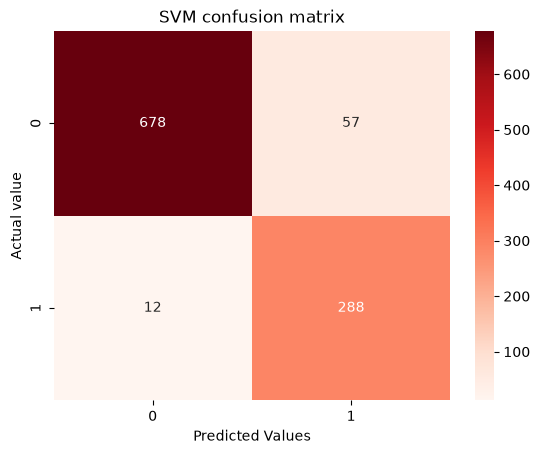

In [16]:
svm_cm = confusion_matrix(
    y_test, svm_pred_model
)
print("SVM Confusion Matrix")
print(svm_cm)

sns.heatmap(svm_cm, annot = True, fmt="d", cmap="Reds")
plt.title("SVM confusion matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual value")
plt.show()

In [17]:
results = pd.DataFrame({
    "Model":["KNN", "SVM"],
    "Accuracy":[
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, svm_pred_model)
    ],
    "Precision":[
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, svm_pred_model)
    ],
    "F1 Score":[
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, svm_pred_model)
    ]
})
print(results)

  Model  Accuracy  Precision  F1 Score
0   KNN  0.833816   0.643498  0.769437
1   SVM  0.933333   0.834783  0.893023
